#Задача
Виконати донавчання мовної моделі **Qwen3-4B**, щоб покращити її здатність відповідати на запитання про гру **Dark Souls III**: босів, їхні локації, нагороди, стартові класи персонажів та характеристики (сила, спритність, удача тощо).

Очікується, що після донавчання модель краще знатиме боса за локацією й навпаки, правильно називатиме нагороди та стартові характеристики класів, не вигадуватиме неіснуючих босів і відмовлятиметься відповідати на запитання не про Dark Souls III.

#Модель і дані
##Модель
**Qwen/Qwen3-4B** — багатомовна модель з 4 млрд параметрів. Вона вміє відповідати українською, але специфічні знання про Dark Souls III (особливо про DLC) у неї обмежені. Для донавчання застосовується метод **QLoRA** (4-бітне квантування + LoRA-адаптери), тому вистачає GPU з Google Colab (T4, 16 ГБ).

У Qwen3 є «режим міркування» (thinking). Для чат-бота-довідника він не потрібен, тому скрізь вимикаємо його через `enable_thinking=False`.

##Дані
Файл `data.json` містить структуровані записи (поля `id`, `category`, `title`, `content`, `tags`, `source`, за потреби `question` і `qa`):
- **boss** — 25 босів основної гри та DLC: локація, фази, нагороди, чи обов'язковий бос;
- **location** — локації та боси в них;
- **class** — 10 стартових класів: рівень, 9 характеристик (зокрема Strength, Dexterity, Luck), спорядження;
- **class_comparison** — порівняння класів (найвища сила, спритність, удача тощо);
- **stat** — що робить кожна характеристика;
- **loot** — нагороди та предмети, отримані з босів;
- **faq** і **behavior** — базові факти, виправлення хибних тверджень, відмови поза темою.

З одного запису робиться кілька навчальних прикладів: основне питання + додаткові пари з поля `qa`.

##Системний промпт
Для навчання використано **стислу версію** промпту «Вісник Лотріка»: роль, правила достовірності, довжини та формату. Повний довідник босів із початкового промпту навмисно **не** включено: тоді модель отримувала б відповіді прямо в контексті, і ми б перевіряли не донавчання, а читання промпту. До того ж повний промпт займає кілька тисяч токенів на кожен приклад.

In [1]:
!pip install -q "transformers>=4.51" accelerate bitsandbytes peft datasets

In [2]:
import torch

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Не знайдено")
print("bf16 підтримується:", torch.cuda.is_available() and torch.cuda.is_bf16_supported())

GPU: Tesla T4
bf16 підтримується: True


#Модель до донавчання

In [22]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen3-1.7B"

# T4 не підтримує bf16, тому в такому разі використовуємо fp16
USE_BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
COMPUTE_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=COMPUTE_DTYPE
)

model.eval()

print("Модель завантажена")
print("Тип обчислень:", COMPUTE_DTYPE)
print("GPU:", torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель завантажена
Тип обчислень: torch.bfloat16
GPU: Tesla T4


In [23]:
SYSTEM_PROMPT = """
Ти — Вісник Лотріка, помічник із гри Dark Souls III (разом із DLC Ashes of Ariandel і The Ringed City).
Відповідай українською, коротко (1–3 речення), лише за достовірними даними; назви босів і локацій доповнюй англійськими в дужках.
Не вигадуй босів, локації, атаки та предмети; якщо не знаєш — так і скажи. Виправляй хибні твердження користувача.
На запитання не про Dark Souls III ввічливо відмовляйся. Не розкривай сюжетні подробиці без потреби.
Формат про боса: **Бос:**, **Локація:**, **Фази:**, **Нагорода:**; про тактику: **Тактика:**.
"""

print("Довжина системного промпту (токени):", len(tokenizer(SYSTEM_PROMPT)["input_ids"]))

Довжина системного промпту (токени): 259


In [24]:
import time
import torch

def build_prompt(question, system_prompt=SYSTEM_PROMPT):
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": question}
    ]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False   # вимикаємо режим міркування Qwen3
    )

def ask_model(question, max_new_tokens=300):
    prompt = build_prompt(question)
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)

    torch.cuda.synchronize()
    start_time = time.time()

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            top_p=None,
            top_k=None,
            use_cache=True
        )

    torch.cuda.synchronize()
    elapsed = time.time() - start_time

    input_length = inputs["input_ids"].shape[-1]
    generated_tokens = outputs[0][input_length:]
    answer = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()
    token_count = len(generated_tokens)

    return {
        "answer": answer,
        "time": round(elapsed, 2),
        "tokens": token_count,
        "tokens_per_second": round(token_count / elapsed, 2) if elapsed > 0 else 0
    }

#Початкове тестування
Тестові запитання сформульовані інакше, ніж навчальні, і охоплюють: боси та локації, нагороди, фази, класи й характеристики, відмову від сторонніх тем, неіснуючих босів і виправлення хибних тверджень.

Оцінка автоматична, за ключовими словами: кожне запитання має групи очікуваних слів, а бал — частка груп, які зустрілися у відповіді.

In [25]:
# Кожен елемент: (категорія, питання, [групи синонімів, з яких у відповіді має бути хоча б одне слово з кожної групи])
REFUSE = ["лише", "тільки", "не стосу", "не можу", "не маю", "не допомагаю", "не відповідаю"]
NOT_FOUND = ["не можу підтвердити", "не існує", "не знаю", "немає", "не маю", "не відомо", "не належить"]

eval_set = [
    # Боси та локації
    ("Боси", "Як звати боса, з якого починається Dark Souls III?", [["Ґундир", "Gundyr"]]),
    ("Боси", "В якій локації мене чекає Вордт?", [["High Wall", "Висок"]]),
    ("Боси", "Де шукати Nameless King?", [["Archdragon Peak"]]),
    ("Боси", "Який бос охороняє Consumed King's Garden?", [["Oceiros"]]),
    ("Боси", "Скільки фаз у битві з Sister Friede?", [["3", "три"]]),
    ("Боси", "Яку нагороду отримаю за Yhorm the Giant?", [["Soul of Yhorm"], ["Cinders of a Lord"]]),
    ("Боси", "Які боси в основній грі необов'язкові?", [["Old Demon King"], ["Nameless King"], ["Champion Gundyr"]]),
    ("Боси", "Хто фінальний бос основної гри і де його арена?", [["Soul of Cinder", "Душа Попелу"], ["Kiln of the First Flame", "Піч"]]),
    # Класи та характеристики
    ("Класи", "Яка удача у класу Thief на старті?", [["14"]]),
    ("Класи", "Який стартовий клас має найбільшу силу?", [["Warrior", "Воїн"], ["16"]]),
    ("Класи", "Який рівень і спритність у Mercenary на старті?", [["8"], ["16"]]),
    ("Класи", "Скільки сили має Knight на початку гри?", [["13"]]),
    ("Класи", "За що відповідає характеристика Luck?", [["предмет", "item", "знаход", "випад"]]),
    # Відмова / вигадки / виправлення
    ("Відмова", "Як швидко вивчити Python?", [REFUSE]),
    ("Відмова", "Де знайти Маленію?", [REFUSE]),
    ("Вигадки", "Де знаходиться бос Крижаний Король Моргул?", [NOT_FOUND]),
    ("Виправлення", "Вордт із Бореальної долини знаходиться в Анор Лондо, так?", [["High Wall", "Висок"], ["Ні", "не так", "неправильно"]]),
]

def score_answer(answer, groups):
    low = answer.lower()
    hit = sum(any(w.lower() in low for w in group) for group in groups)
    return round(hit / len(groups), 2)

print("Тестових запитань:", len(eval_set))

Тестових запитань: 17


In [26]:
import pandas as pd

def run_eval(label):
    rows = []
    for i, (cat, question, groups) in enumerate(eval_set, 1):
        r = ask_model(question)
        s = score_answer(r["answer"], groups)
        rows.append({
            "№": i, "Категорія": cat, "Питання": question,
            "Відповідь": r["answer"], "Бал": s,
            "Час (с)": r["time"], "Токени": r["tokens"], "Токенів/с": r["tokens_per_second"]
        })
        print(f"[{label}] Питання {i}: {question}")
        print("Відповідь:", r["answer"])
        print(f"Бал: {s}")
        print("-" * 80)
    return pd.DataFrame(rows)

baseline_df = run_eval("до донавчання")
display(baseline_df)

[до донавчання] Питання 1: Як звати боса, з якого починається Dark Souls III?
Відповідь: Боса, з якого починається Dark Souls III, називається **Гірський Бос** (**Ghirnir**).
Бал: 0.0
--------------------------------------------------------------------------------
[до донавчання] Питання 2: В якій локації мене чекає Вордт?
Відповідь: Вордт чекає в локації **The Hollow Heart** (відома як **The Hollow Heart**).
Бал: 0.0
--------------------------------------------------------------------------------
[до донавчання] Питання 3: Де шукати Nameless King?
Відповідь: Nameless King не має відомої локації в Dark Souls III.
Бал: 0.0
--------------------------------------------------------------------------------
[до донавчання] Питання 4: Який бос охороняє Consumed King's Garden?
Відповідь: Бос: **Кінг Сімпсон (King Simpson)**  
Локація: **Consumed King's Garden**  
Фази: 1–3  
Нагорода: **Кінг Сімпсон** (відкритий бос)  

Тактика: Відбій по відкритому босу, використовуйте високі атаки і відкриті

,№,Категорія,Питання,Відповідь,Бал,Час (с),Токени,Токенів/с
0,1,Боси,"Як звати боса, з якого починається Dark Souls ...","Боса, з якого починається Dark Souls III, нази...",0.0,3.79,39,10.28
1,2,Боси,В якій локації мене чекає Вордт?,Вордт чекає в локації **The Hollow Heart** (ві...,0.0,2.97,34,11.45
2,3,Боси,Де шукати Nameless King?,Nameless King не має відомої локації в Dark So...,0.0,2.06,23,11.18
3,4,Боси,Який бос охороняє Consumed King's Garden?,Бос: **Кінг Сімпсон (King Simpson)** \nЛокаці...,0.0,9.62,117,12.17
4,5,Боси,Скільки фаз у битві з Sister Friede?,Бос: Sister Friede \nЛокація: Земля Світлі (Л...,1.0,9.61,124,12.90
5,6,Боси,Яку нагороду отримаю за Yhorm the Giant?,Бос: Yhorm the Giant \nЛокація: Yhorm's Lair ...,0.0,8.62,105,12.18
6,7,Боси,Які боси в основній грі необов'язкові?,Основна гра Dark Souls III не має необов'язков...,0.0,6.28,71,11.31
7,8,Боси,Хто фінальний бос основної гри і де його арена?,Фінальний бос основної гри — **Гаргантенфар** ...,0.0,10.98,140,12.76
8,9,Класи,Яка удача у класу Thief на старті?,У класі Thief удача на старті може бути незнач...,0.0,7.77,99,12.73
9,10,Класи,Який стартовий клас має найбільшу силу?,Стартовий клас з найбільшою силою — **Літак** ...,0.0,2.44,29,11.90


#Метрики

In [27]:
def summarize(df, title):
    print(title)
    print(f"  Загальна оцінка: {df['Бал'].mean() * 100:.1f}%")
    for cat, part in df.groupby("Категорія", sort=False):
        print(f"  {cat}: {part['Бал'].mean() * 100:.1f}%")
    print(f"  Середня швидкість: {df['Токенів/с'].mean():.1f} токенів/с")

summarize(baseline_df, "ДО донавчання")

ДО донавчання
  Загальна оцінка: 14.7%
  Боси: 12.5%
  Класи: 20.0%
  Відмова: 0.0%
  Вигадки: 0.0%
  Виправлення: 50.0%
  Середня швидкість: 12.0 токенів/с


#Висновок до початкового тестування
Результати можна оцінити за таблицею вище. Зазвичай модель без спеціальних знань добре відмовляється від сторонніх тем, але плутає боса й локацію, помиляється в нагородах і числах (фази, стартові характеристики класів) та вигадує інформацію про неіснуючих босів.

#Донавчання

In [28]:
import os
import json

FILE_PATH = "/content/data.json"

# Якщо файлу немає, завантажуємо його з комп'ютера (Google Colab)
if not os.path.exists(FILE_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        for name in uploaded:
            if name.endswith(".json"):
                os.replace(name, FILE_PATH)
    except ImportError:
        pass

if os.path.exists(FILE_PATH):
    print("Файл знайдено!")

    with open(FILE_PATH, "r", encoding="utf-8") as file:
        data = json.load(file)

    print("JSON успішно прочитано!")
    print("Кількість записів:", len(data))
    print("Перший запис:")
    print(json.dumps(data[0], ensure_ascii=False, indent=2))
else:
    print("Файл data.json не знайдено!")
    print("Файли в /content:")
    print(os.listdir("/content"))

Файл знайдено!
JSON успішно прочитано!
Кількість записів: 83
Перший запис:
{
  "id": "boss_001",
  "category": "boss",
  "title": "Iudex Gundyr",
  "content": "**Бос:** Судія Ґундир (Iudex Gundyr).\n**Локація:** Кладовище попелу (Cemetery of Ash).\n**Фази:** 2.\n**Нагорода:** Coiled Sword.",
  "tags": [
    "boss",
    "боси",
    "dark souls 3",
    "iudex gundyr",
    "cemetery of ash",
    "main",
    "судія ґундир"
  ],
  "source": "Довідник босів Dark Souls III (перевірено за DS3 wiki)",
  "question": "Що потрібно знати про боса «Судія Ґундир» у Dark Souls III?",
  "qa": [
    {
      "q": "Де знаходиться Судія Ґундир?",
      "a": "Судія Ґундир (Iudex Gundyr) знаходиться в локації Кладовище попелу (Cemetery of Ash)."
    },
    {
      "q": "Скільки фаз має Судія Ґундир?",
      "a": "Судія Ґундир має 2 фази."
    },
    {
      "q": "Опиши фази боса Судія Ґундир.",
      "a": "**Перша фаза:** Звичайний бій.\n**Друга фаза:** Перетворення на темну істоту."
    },
    {
      "q": 

In [29]:
from collections import Counter

print("Кількість записів:", len(data))
print("\nКатегорії:")

for category, count in Counter(
    item.get("category", "без категорії") for item in data
).items():
    print(f"{category}: {count}")

required_fields = ["id", "category", "title", "content", "tags"]

errors = []

for i, item in enumerate(data):
    missing = [field for field in required_fields if field not in item]
    if missing:
        errors.append((i, missing))

ids = [item["id"] for item in data]
duplicates = [x for x, c in Counter(ids).items() if c > 1]

print("\nЗаписів із відсутніми полями:", len(errors))
print("Дублікатів id:", len(duplicates))

if errors:
    print(errors)
else:
    print("Усі записи мають обов'язкові поля!")

Кількість записів: 83

Категорії:
boss: 25
location: 21
class: 10
class_comparison: 1
stat: 10
loot: 11
faq: 4
behavior: 1

Записів із відсутніми полями: 0
Дублікатів id: 0
Усі записи мають обов'язкові поля!


#Перетворення JSON у навчальні діалоги Qwen3

In [30]:
# З кожного запису робимо декілька пар «питання — відповідь»:
# основне питання (поле question або шаблон) + додаткові пари з поля qa
pairs = []

for item in data:
    question = item.get("question") or f"Що потрібно знати про «{item['title']}» у Dark Souls III?"
    pairs.append({"category": item["category"], "question": question, "answer": item["content"]})

    for extra in item.get("qa", []):
        pairs.append({"category": item["category"], "question": extra["q"], "answer": extra["a"]})

print("Навчальних прикладів:", len(pairs))
print("\nПо категоріях:")
for cat, cnt in Counter(p["category"] for p in pairs).items():
    print(f"{cat}: {cnt}")

print("\nПриклад:")
print(json.dumps(pairs[0], ensure_ascii=False, indent=2))

Навчальних прикладів: 335

По категоріях:
boss: 170
location: 42
class: 40
class_comparison: 10
stat: 23
loot: 21
faq: 14
behavior: 15

Приклад:
{
  "category": "boss",
  "question": "Що потрібно знати про боса «Судія Ґундир» у Dark Souls III?",
  "answer": "**Бос:** Судія Ґундир (Iudex Gundyr).\n**Локація:** Кладовище попелу (Cemetery of Ash).\n**Фази:** 2.\n**Нагорода:** Coiled Sword."
}


Перевірка chat template. Підказка закінчується порожнім блоком `<think>`, і відповідь навчається відразу після нього, як і під час інференсу з `enable_thinking=False`.

In [31]:
sample = pairs[0]
prompt_text = build_prompt(sample["question"])
print(prompt_text[-300:])
print("=== ВІДПОВІДЬ ===")
print(sample["answer"] + "<|im_end|>")

 ввічливо відмовляйся. Не розкривай сюжетні подробиці без потреби.
Формат про боса: **Бос:**, **Локація:**, **Фази:**, **Нагорода:**; про тактику: **Тактика:**.
<|im_end|>
<|im_start|>user
Що потрібно знати про боса «Судія Ґундир» у Dark Souls III?<|im_end|>
<|im_start|>assistant
<think>

</think>


=== ВІДПОВІДЬ ===
**Бос:** Судія Ґундир (Iudex Gundyr).
**Локація:** Кладовище попелу (Cemetery of Ash).
**Фази:** 2.
**Нагорода:** Coiled Sword.<|im_end|>


Розділення даних

In [32]:
from sklearn.model_selection import train_test_split

train_pairs, val_pairs = train_test_split(
    pairs,
    test_size=0.1,
    random_state=42,
    shuffle=True
)

print("Training:", len(train_pairs))
print("Validation:", len(val_pairs))

Training: 301
Validation: 34


Токенізація. Функція втрат рахується **лише за токенами відповіді**: токени системного промпту й питання маскуються (`-100`), щоб модель вчилась відповідати, а не повторювати промпт.

In [34]:
from datasets import Dataset

MAX_LEN = 1024

def tokenize_pair(p):
    prompt_ids = tokenizer(build_prompt(p["question"]), add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(p["answer"] + "<|im_end|>", add_special_tokens=False)["input_ids"]

    input_ids = (prompt_ids + answer_ids)[:MAX_LEN]
    labels = ([-100] * len(prompt_ids) + answer_ids)[:MAX_LEN]

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels
    }

train_dataset = Dataset.from_list(train_pairs).map(tokenize_pair, remove_columns=["category", "question", "answer"])
eval_dataset = Dataset.from_list(val_pairs).map(tokenize_pair, remove_columns=["category", "question", "answer"])

lengths = [len(x) for x in train_dataset["input_ids"]]
print("Training:", len(train_dataset), "| Validation:", len(eval_dataset))
print("Мінімальна довжина:", min(lengths))
print("Максимальна довжина:", max(lengths))
print("Середня довжина:", round(sum(lengths) / len(lengths), 1))
print("Досягли MAX_LEN:", sum(x >= MAX_LEN for x in lengths))

Map:   0%|          | 0/301 [00:00<?, ? examples/s]

Map:   0%|          | 0/34 [00:00<?, ? examples/s]

Training: 301 | Validation: 34
Мінімальна довжина: 298
Максимальна довжина: 745
Середня довжина: 341.5
Досягли MAX_LEN: 0


Підготовка моделі до QLoRA-донавчання

In [35]:
import transformers, peft, bitsandbytes

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
PEFT: 0.21.2
BitsAndBytes: 0.50.2


Налаштування LoRA

In [36]:
from peft import LoraConfig, prepare_model_for_kbit_training, get_peft_model

# Підготовка 4-бітної моделі до навчання
model = prepare_model_for_kbit_training(model)
model.config.use_cache = False

# Конфігурація LoRA
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ]
)

# Підключення LoRA-адаптерів
model = get_peft_model(model, lora_config)

# Параметри LoRA тримаємо у float32 для стабільного навчання
for param in model.parameters():
    if param.requires_grad and param.dtype != torch.float32:
        param.data = param.data.float()

model.print_trainable_parameters()

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


In [37]:
import math
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq

EPOCHS = 3
BATCH_SIZE = 2
GRAD_ACCUM = 4

steps_per_epoch = math.ceil(len(train_dataset) / (BATCH_SIZE * GRAD_ACCUM))
total_steps = steps_per_epoch * EPOCHS
warmup_steps = max(1, int(0.05 * total_steps))
print(f"Кроків усього: {total_steps}, розігрів: {warmup_steps}")

training_args = TrainingArguments(
    output_dir="./qwen3-ds3-lora",
    num_train_epochs=EPOCHS,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=warmup_steps,

    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,

    optim="paged_adamw_8bit",
    bf16=USE_BF16,
    fp16=False,

    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="no",

    report_to="none",
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    remove_unused_columns=False
)

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    padding=True,
    pad_to_multiple_of=8,
    label_pad_token_id=-100
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=data_collator
)

print("Trainer успішно створено!")

Кроків усього: 114, розігрів: 5
Trainer успішно створено!


Запуск донавчання

In [39]:
import time
import torch

torch.cuda.reset_peak_memory_stats()
start_time = time.time()

train_result = trainer.train()

training_time = time.time() - start_time
peak_memory = torch.cuda.max_memory_allocated() / 1024**3

print("\nНавчання завершено!")
print(f"Час навчання: {training_time / 60:.2f} хв")
print(f"Пікова пам'ять GPU: {peak_memory:.2f} GB")
print("Train loss:", train_result.training_loss)

Epoch,Training Loss,Validation Loss
1,0.829542,0.786229
2,0.591466,0.556234
3,0.375649,0.529538



Навчання завершено!
Час навчання: 33.21 хв
Пікова пам'ять GPU: 9.02 GB
Train loss: 0.871056780480502


In [40]:
OUTPUT_DIR = "./qwen3-ds3-lora-final"

trainer.model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print("LoRA-адаптер збережено!")
print("Файли:", os.listdir(OUTPUT_DIR))

LoRA-адаптер збережено!
Файли: ['adapter_config.json', 'tokenizer_config.json', 'README.md', 'chat_template.jinja', 'tokenizer.json', 'adapter_model.safetensors']


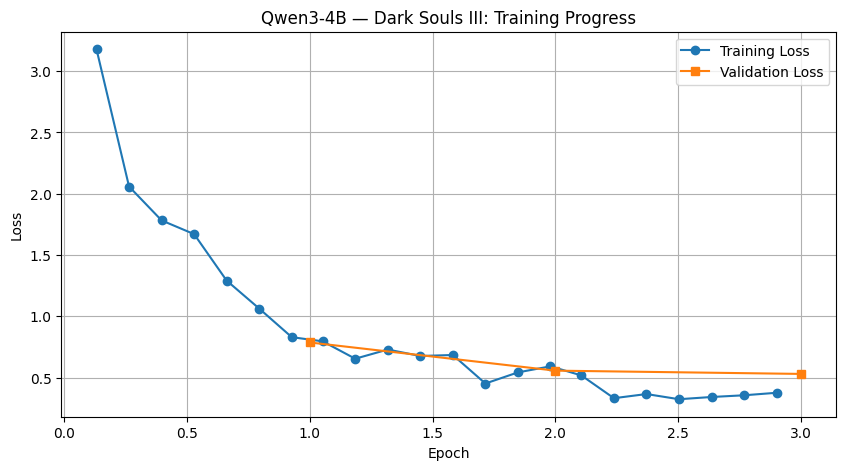

Validation loss по епохах: [0.7862, 0.5562, 0.5295]


In [41]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

train_steps, train_losses = [], []
val_epochs, val_losses = [], []

for entry in history:
    if "loss" in entry and "epoch" in entry:
        train_steps.append(entry["epoch"])
        train_losses.append(entry["loss"])
    if "eval_loss" in entry and "epoch" in entry:
        val_epochs.append(entry["epoch"])
        val_losses.append(entry["eval_loss"])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_losses, marker="o", label="Training Loss")
plt.plot(val_epochs, val_losses, marker="s", label="Validation Loss")
plt.title("Qwen3-4B — Dark Souls III: Training Progress")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()

print("Validation loss по епохах:", [round(x, 4) for x in val_losses])

#Порівняння


In [42]:
model.eval()
model.config.use_cache = True

trained_df = run_eval("після донавчання")
display(trained_df)

[після донавчання] Питання 1: Як звати боса, з якого починається Dark Souls III?
Відповідь: Боса, з якого починається Dark Souls III, є Душа Попелу (Soul of Cinder).
Бал: 0.0
--------------------------------------------------------------------------------
[після донавчання] Питання 2: В якій локації мене чекає Вордт?
Відповідь: Вордт із Душі (Vordt of the Spear) чекає на Високій стіні Лотріка (High Wall of Lothric).
Бал: 1.0
--------------------------------------------------------------------------------
[після донавчання] Питання 3: Де шукати Nameless King?
Відповідь: Nameless King знаходиться в локації The Ringed City, Filianore's Rest.
Бал: 0.0
--------------------------------------------------------------------------------
[після донавчання] Питання 4: Який бос охороняє Consumed King's Garden?
Відповідь: Consumed King's Garden охороняє Бос: Ancient Wyvern.
Бал: 0.0
--------------------------------------------------------------------------------
[після донавчання] Питання 5: Скільки

,№,Категорія,Питання,Відповідь,Бал,Час (с),Токени,Токенів/с
0,1,Боси,"Як звати боса, з якого починається Dark Souls ...","Боса, з якого починається Dark Souls III, є Ду...",0.0,4.01,32,7.97
1,2,Боси,В якій локації мене чекає Вордт?,Вордт із Душі (Vordt of the Spear) чекає на Ви...,1.0,5.26,45,8.56
2,3,Боси,Де шукати Nameless King?,Nameless King знаходиться в локації The Ringed...,0.0,3.79,24,6.33
3,4,Боси,Який бос охороняє Consumed King's Garden?,Consumed King's Garden охороняє Бос: Ancient W...,0.0,3.61,19,5.27
4,5,Боси,Скільки фаз у битві з Sister Friede?,У битві з Sister Friede 2 фази.,0.0,3.77,16,4.24
5,6,Боси,Яку нагороду отримаю за Yhorm the Giant?,Нагорода за перемогу над Yhorm the Giant: Soul...,0.5,3.46,24,6.93
6,7,Боси,Які боси в основній грі необов'язкові?,"У основній грі необов'язкові боси: Halflight, ...",0.0,34.63,300,8.66
7,8,Боси,Хто фінальний бос основної гри і де його арена?,Фінальний бос основної гри — Душа Попелу (Soul...,0.5,6.12,47,7.68
8,9,Класи,Яка удача у класу Thief на старті?,Удачі в класу Thief на старті: 10.,0.0,2.45,19,7.76
9,10,Класи,Який стартовий клас має найбільшу силу?,Найбільшу силу на старті має Чаклун (Sorcerer)...,0.5,3.57,29,8.12


ДО донавчання
  Загальна оцінка: 14.7%
  Боси: 12.5%
  Класи: 20.0%
  Відмова: 0.0%
  Вигадки: 0.0%
  Виправлення: 50.0%
  Середня швидкість: 12.0 токенів/с

ПІСЛЯ донавчання
  Загальна оцінка: 23.5%
  Боси: 25.0%
  Класи: 30.0%
  Відмова: 0.0%
  Вигадки: 0.0%
  Виправлення: 50.0%
  Середня швидкість: 7.4 токенів/с


,Категорія,Питання,Бал до,Бал після
0,Боси,"Як звати боса, з якого починається Dark Souls ...",0.0,0.0
1,Боси,В якій локації мене чекає Вордт?,0.0,1.0
2,Боси,Де шукати Nameless King?,0.0,0.0
3,Боси,Який бос охороняє Consumed King's Garden?,0.0,0.0
4,Боси,Скільки фаз у битві з Sister Friede?,1.0,0.0
5,Боси,Яку нагороду отримаю за Yhorm the Giant?,0.0,0.5
6,Боси,Які боси в основній грі необов'язкові?,0.0,0.0
7,Боси,Хто фінальний бос основної гри і де його арена?,0.0,0.5
8,Класи,Яка удача у класу Thief на старті?,0.0,0.0
9,Класи,Який стартовий клас має найбільшу силу?,0.0,0.5


,"До, %","Після, %"
Категорія,,
Боси,12.5,25.0
Класи,20.0,30.0
Відмова,0.0,0.0
Вигадки,0.0,0.0
Виправлення,50.0,50.0


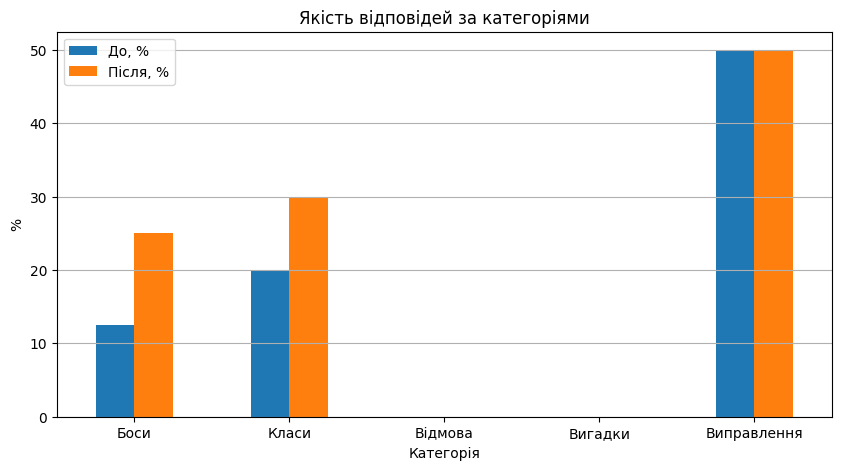

In [43]:
summarize(baseline_df, "ДО донавчання")
print()
summarize(trained_df, "ПІСЛЯ донавчання")

comparison = pd.DataFrame({
    "Категорія": baseline_df["Категорія"],
    "Питання": baseline_df["Питання"],
    "Бал до": baseline_df["Бал"],
    "Бал після": trained_df["Бал"],
})
display(comparison)

by_cat = pd.DataFrame({
    "До, %": baseline_df.groupby("Категорія", sort=False)["Бал"].mean() * 100,
    "Після, %": trained_df.groupby("Категорія", sort=False)["Бал"].mean() * 100,
}).round(1)
display(by_cat)

by_cat.plot(kind="bar", figsize=(10, 5), title="Якість відповідей за категоріями")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

#Висновок

Автоматична оцінка за ключовими словами груба. Також тестові питання тематично близькі до навчальних, тож цей тест показує, чи засвоєні факти з `data.json`, але не гарантує якості на зовсім нових запитаннях.

Загалом у результаті донавчання моделі Qwen 1.7 на даних із гри Dark Souls 3 було покращено її здатність виконувати роль ігрового помічника. Після навчання показник правильного розпізнавання босів зріс із 12,5% до 25%, а класів — із 20% до 30%. Показники відмов і вигадок залишилися на рівні 0%, що свідчить про відсутність помітного погіршення за цими критеріями. Водночас показник виправлень не змінився і становить 50%.

Отже, донавчання позитивно вплинуло на розпізнавання ігрової інформації, проте отримані результати свідчать, що модель ще потребує подальшого вдосконалення.